### Geometric Brownian Motion

$$
dS(t) = \mu S(t)dt + \sigma S(t) dW(t),
$$
where $W(t)$ is a Wiener process, $\mu, \sigma$ are constants.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from copy import copy

In [ ]:
mu = 0.1
sigma = 1
N_traj = 10000
S0 = np.ones(N_traj)
dts = dts = np.logspace(-4, 0, 6)

def GBM_sim(N_traj, S0, mu, sigma, dts):
    results = {}

    for dt in dts:
        N = int(1 / dt)
        times = np.linspace(0, 1, N + 1)

        dW = np.sqrt(dt) * np.random.randn(N, N_traj)
        W = np.vstack([np.zeros(N_traj), np.cumsum(dW, axis=0)])

        S_em = np.zeros((N + 1, N_traj))
        S_em[0] = S0

        for n in range(N):
            S_em[n + 1] = (
                S_em[n]
                + mu * S_em[n] * dt
                + sigma * S_em[n] * dW[n]
            )

        S_exact = S0 * np.exp(
            (mu - sigma**2 / 2) * times[:, None]
            + sigma * W
        )

        error = np.sqrt(np.mean((S_em[-1] - S_exact[-1])**2))

        results[dt] = {
            "times": times,
            "S_em": S_em,
            "S_exact": S_exact,
            "error": error,
            "mean_em": np.mean(S_em, axis=1),
            "var_em": np.var(S_em, axis=1),
            "mean_exact": np.mean(S_exact, axis=1),
            "var_exact": np.var(S_exact, axis=1)
        }

    return results

results = GBM_sim(N_traj, S0, mu, sigma, dts)

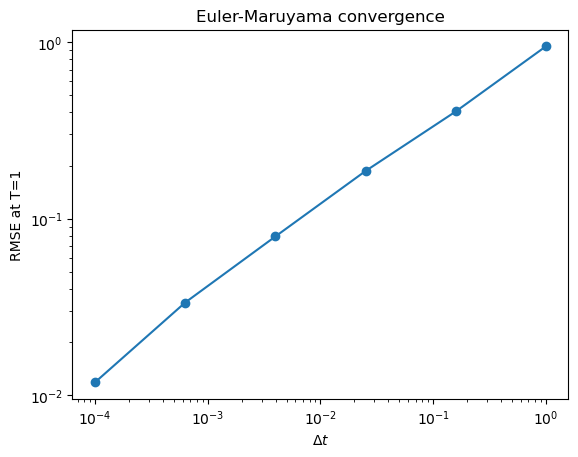

In [9]:
errors = [results[dt]["error"] for dt in dts]

plt.loglog(dts, errors, 'o-')
plt.xlabel(r'$\Delta t$')
plt.ylabel('RMSE at T=1')
plt.title('Euler-Maruyama convergence')
plt.show()

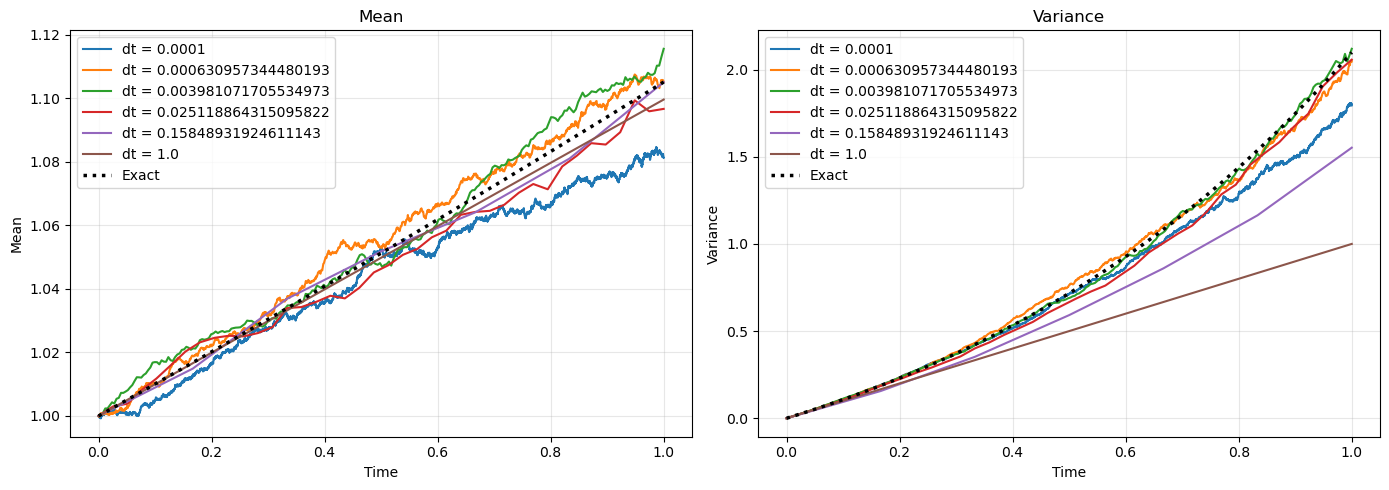

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for dt in dts:
    r = results[dt]
    axes[0].plot(
        r["times"], r["mean_em"],
        label=f"dt = {dt}"
    )
    axes[1].plot(
        r["times"], r["var_em"],
        label=f"dt = {dt}"
    )

t = np.linspace(0, 1, 500)

mean_exact = np.exp(mu * t)
var_exact = np.exp(2 * mu * t) * (np.exp(sigma**2 * t) - 1)

axes[0].plot(t, mean_exact, "k:", linewidth=2.5, label="Exact")
axes[1].plot(t, var_exact, "k:", linewidth=2.5, label="Exact")

axes[0].set_title("Mean")
axes[1].set_title("Variance")

for ax in axes:
    ax.set_xlabel("Time")
    ax.legend()
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Mean")
axes[1].set_ylabel("Variance")

plt.tight_layout()
plt.show()
